# Convolutional Neural Network

### Importing the libraries

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [2]:
tf.__version__

'2.21.0'

## Part 1 - Data Preprocessing

### Preprocessing the Training set

In [3]:
train_datagen = ImageDataGenerator(rescale = 1./255,
                                   shear_range = 0.2,
                                   zoom_range = 0.2,
                                   horizontal_flip = True)
training_set = train_datagen.flow_from_directory('dataset/training_set',
                                                 target_size = (64, 64),
                                                 batch_size = 32,
                                                 class_mode = 'binary')

Found 8000 images belonging to 2 classes.


### Preprocessing the Test set

In [4]:
test_datagen = ImageDataGenerator(rescale = 1./255)
test_set = test_datagen.flow_from_directory('dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary')

Found 2000 images belonging to 2 classes.


## Part 2 - Building the CNN

### Initialising the CNN

In [5]:
cnn = tf.keras.models.Sequential()

### Step 1 - Convolution

In [6]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu', input_shape=[64, 64, 3]))

C:\Users\pulki\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


### Step 2 - Pooling

In [7]:
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Adding a second convolutional layer

In [8]:
cnn.add(tf.keras.layers.Conv2D(filters=32, kernel_size=3, activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2, strides=2))

### Step 3 - Flattening

In [9]:
cnn.add(tf.keras.layers.Flatten())

### Step 4 - Full Connection

In [10]:
cnn.add(tf.keras.layers.Dense(units=128, activation='relu'))

### Step 5 - Output Layer

In [11]:
cnn.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

## Part 3 - Training the CNN

### Compiling the CNN

In [12]:
cnn.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

### Training the CNN on the Training set and evaluating it on the Test set

In [13]:
%pip install pillow

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [14]:
cnn.fit(x = training_set, validation_data = test_set, epochs = 30)

Epoch 1/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 40ms/step - accuracy: 0.6018 - loss: 0.6596 - val_accuracy: 0.6605 - val_loss: 0.6080
Epoch 2/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.6739 - loss: 0.5980 - val_accuracy: 0.7140 - val_loss: 0.5574
Epoch 3/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.7107 - loss: 0.5552 - val_accuracy: 0.7090 - val_loss: 0.5634
Epoch 4/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.7445 - loss: 0.5149 - val_accuracy: 0.7510 - val_loss: 0.4965
Epoch 5/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.7548 - loss: 0.4989 - val_accuracy: 0.7490 - val_loss: 0.5003
Epoch 6/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.7797 - loss: 0.4645 - val_accuracy: 0.7455 - val_loss: 0.5256
Epoch 7/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.7804 - loss: 0.4609 - val_accuracy: 0.7860 - val_loss: 0.4647
Epoch 8/30
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 39ms/step - accuracy: 0.7914 - loss: 0.4441 - 

## Part 4 - Making a single prediction

In [15]:
%pip install numpy

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [16]:
import numpy as np
from tensorflow.keras.preprocessing import image
test_image = image.load_img('dataset/single_prediction/cat_or_dog_1.jpg', target_size = (64, 64))
test_image = image.img_to_array(test_image)
test_image = np.expand_dims(test_image, axis = 0)
result = cnn.predict(test_image)
training_set.class_indices
if result[0][0] == 1:
  prediction = 'dog'
else:
  prediction = 'cat'

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step


In [17]:
print(prediction)

dog


In [18]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.3 MB 5.4 MB/s eta 0:00:02
   ----------- ---------------------------- 2.6/9.3 MB 8.9 MB/s eta 0:00:01
   -------------- ------------------------- 3.4/9.3 MB 8.5 MB/s eta 0:00:01
   ------------------- -------------------- 4.5/9.3 MB 7.0 MB/s eta 0:00:01
   ----------------------- ---------------- 5.5/9.3 MB 5.8 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.3 MB 5.2 MB/s eta 0:00:01
   -------------------------- ------------- 6.3/9.3 MB 5.1 MB/s eta 0:00:01
   ------------------------------- -------- 7.3/9.3 MB 4.7 MB/s eta 0:00

In [20]:
%pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import roc_curve, auc

# Folder name for each class index, e.g. {0: 'cats', 1: 'dogs'}
idx_to_class = {v: k for k, v in training_set.class_indices.items()}
class_names = [idx_to_class[i] for i in range(len(idx_to_class))]

# Evaluation generator with shuffle=False, so predictions line up with their labels and file paths
eval_set = test_datagen.flow_from_directory('dataset/test_set',
                                            target_size = (64, 64),
                                            batch_size = 32,
                                            class_mode = 'binary',
                                            shuffle = False)

def predict_with_confidence(x):
    """Returns (predicted class index, confidence in that class) for a batch."""
    p = cnn.predict(x, verbose=0).ravel()
    pred = (p > 0.5).astype(int)
    conf = np.where(pred == 1, p, 1 - p)
    return pred, conf

Found 2000 images belonging to 2 classes.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,439,653 (9.31 MB)

 Trainable params: 813,217 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,626,436 (6.20 MB)

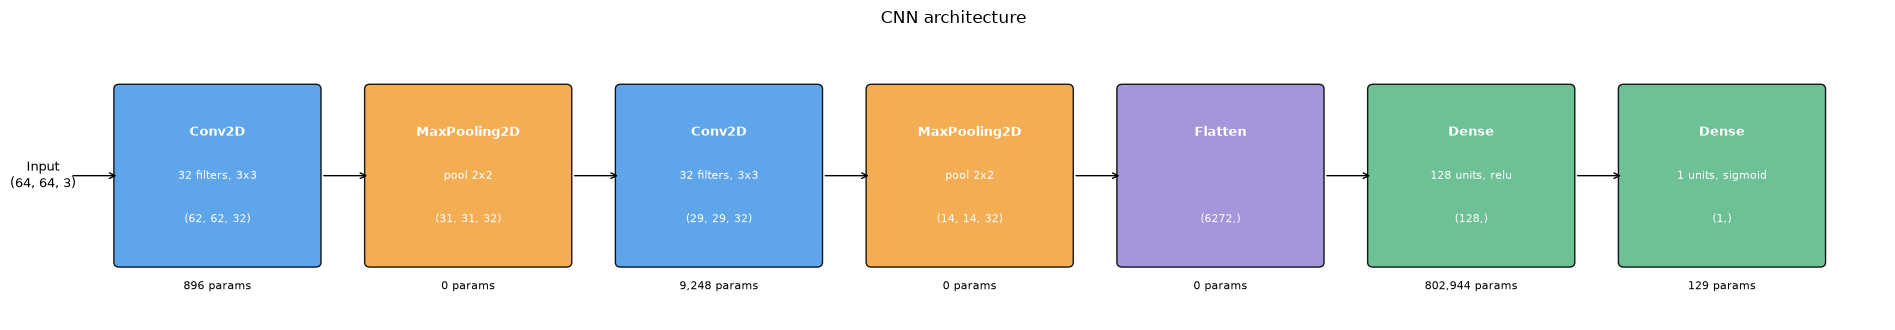

In [34]:
cnn.summary()

# Block diagram of the layers, drawn with matplotlib (no pydot / Graphviz needed)
from matplotlib.patches import FancyBboxPatch

def layer_color(layer):
    if isinstance(layer, tf.keras.layers.Conv2D):    return '#4C9BE8'
    if isinstance(layer, tf.keras.layers.MaxPool2D): return '#F2A541'
    if isinstance(layer, tf.keras.layers.Flatten):   return '#9B8AD6'
    return '#5DBB8A'                                  # Dense

def layer_shape(layer):
    try:
        return tuple(layer.output.shape[1:])
    except Exception:
        return '?'

layers = cnn.layers
fig, ax = plt.subplots(figsize=(3 + 2.3 * len(layers), 3.4))
ax.set_xlim(0, 2.3 * len(layers) + 1.0); ax.set_ylim(0, 3); ax.axis('off')

ax.text(0.2, 1.5, 'Input\n(64, 64, 3)', ha='center', va='center', fontsize=9)
for i, layer in enumerate(layers):
    x = 0.9 + i * 2.3
    ax.add_patch(FancyBboxPatch((x, 0.6), 1.8, 1.8, boxstyle='round,pad=0.05',
                                fc=layer_color(layer), ec='black', alpha=0.9))
    kind = layer.__class__.__name__
    detail = ''
    if isinstance(layer, tf.keras.layers.Conv2D):
        detail = f'{layer.filters} filters, {layer.kernel_size[0]}x{layer.kernel_size[1]}'
    elif isinstance(layer, tf.keras.layers.MaxPool2D):
        detail = f'pool {layer.pool_size[0]}x{layer.pool_size[1]}'
    elif isinstance(layer, tf.keras.layers.Dense):
        detail = f'{layer.units} units, {layer.activation.__name__}'
    ax.text(x + 0.9, 1.95, kind, ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    ax.text(x + 0.9, 1.5, detail, ha='center', va='center', fontsize=8, color='white')
    ax.text(x + 0.9, 1.05, f'{layer_shape(layer)}', ha='center', va='center', fontsize=8, color='white')
    ax.text(x + 0.9, 0.35, f'{layer.count_params():,} params', ha='center', va='center', fontsize=8)
    ax.annotate('', xy=(x, 1.5), xytext=(x - 0.45, 1.5), arrowprops=dict(arrowstyle='->'))
ax.set_title('CNN architecture', fontsize=12)
plt.tight_layout()
plt.show()

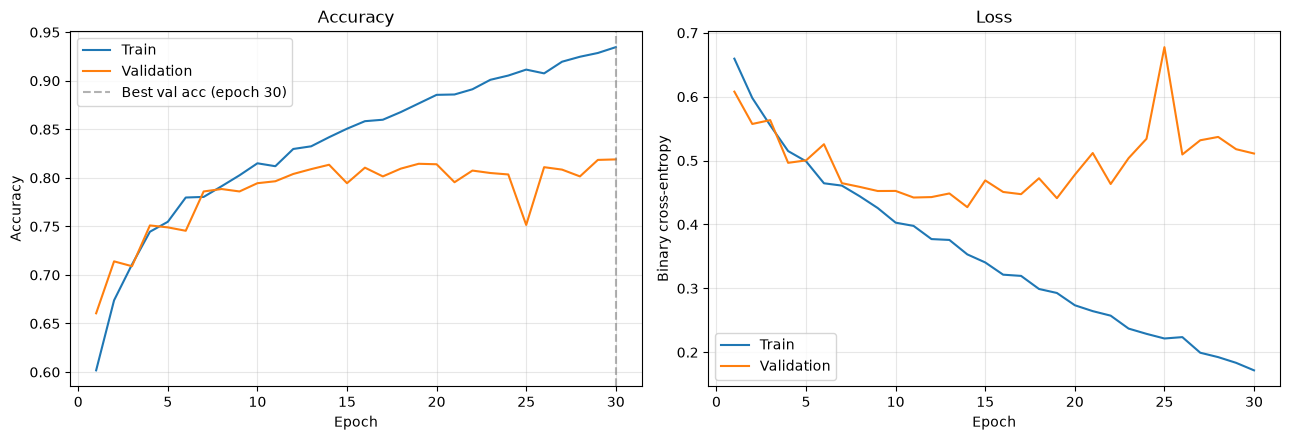

Final train acc: 0.935 | final val acc: 0.819 | gap: 0.116


In [38]:
hist = cnn.history.history
epochs_range = range(1, len(hist['loss']) + 1)
best_epoch = int(np.argmax(hist['val_accuracy'])) + 1

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(epochs_range, hist['accuracy'], label='Train')
ax[0].plot(epochs_range, hist['val_accuracy'], label='Validation')
ax[0].axvline(best_epoch, color='gray', linestyle='--', alpha=0.6,
              label=f'Best val acc (epoch {best_epoch})')
ax[0].set_title('Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
ax[0].legend(); ax[0].grid(alpha=0.3)

ax[1].plot(epochs_range, hist['loss'], label='Train')
ax[1].plot(epochs_range, hist['val_loss'], label='Validation')
ax[1].set_title('Loss'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Binary cross-entropy')
ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

gap = hist['accuracy'][-1] - hist['val_accuracy'][-1]
print(f"Final train acc: {hist['accuracy'][-1]:.3f} | final val acc: {hist['val_accuracy'][-1]:.3f} | gap: {gap:.3f}")

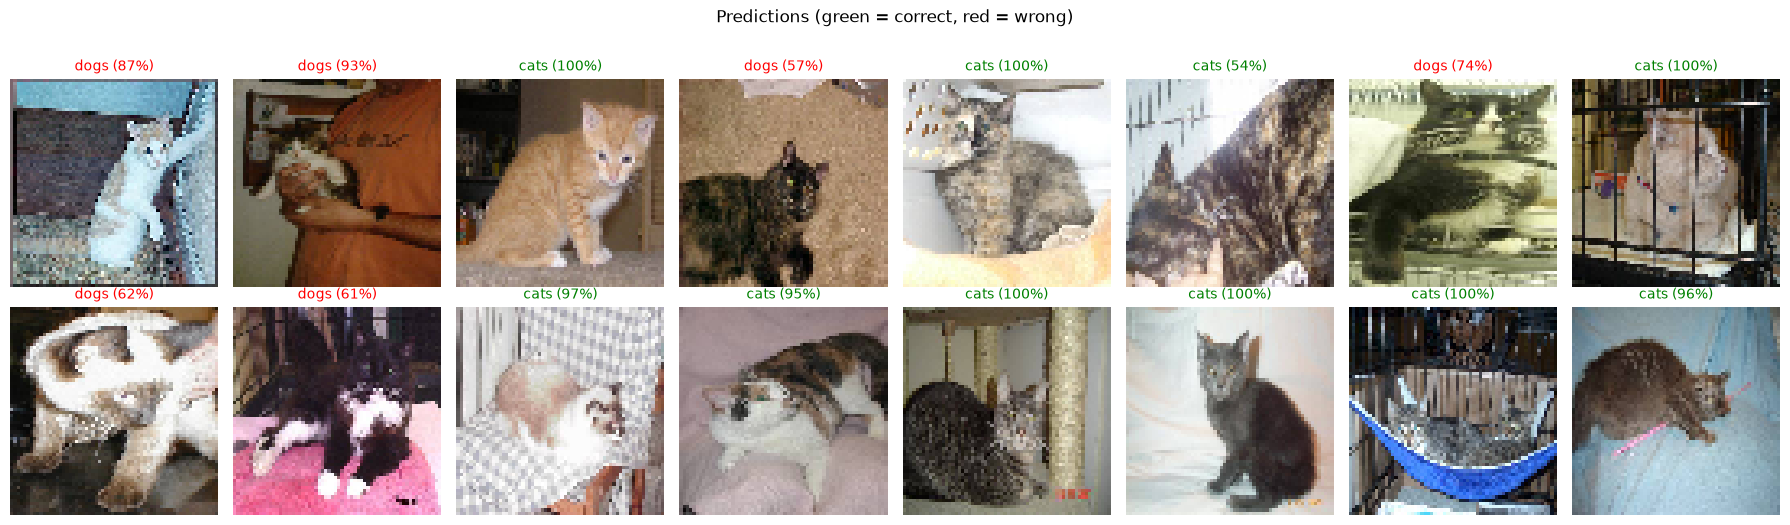

In [39]:
images, labels = eval_set[0]                 # first batch: 32 images, unshuffled
pred, conf = predict_with_confidence(images)

n = 16
fig, axes = plt.subplots(2, 8, figsize=(18, 5.2))
for i, ax in enumerate(axes.ravel()[:n]):
    ax.imshow(images[i])
    correct = pred[i] == int(labels[i])
    ax.set_title(f"{class_names[pred[i]]} ({conf[i]*100:.0f}%)",
                 color='green' if correct else 'red', fontsize=10)
    ax.axis('off')
fig.suptitle('Predictions (green = correct, red = wrong)', y=1.02)
plt.tight_layout()
plt.show()

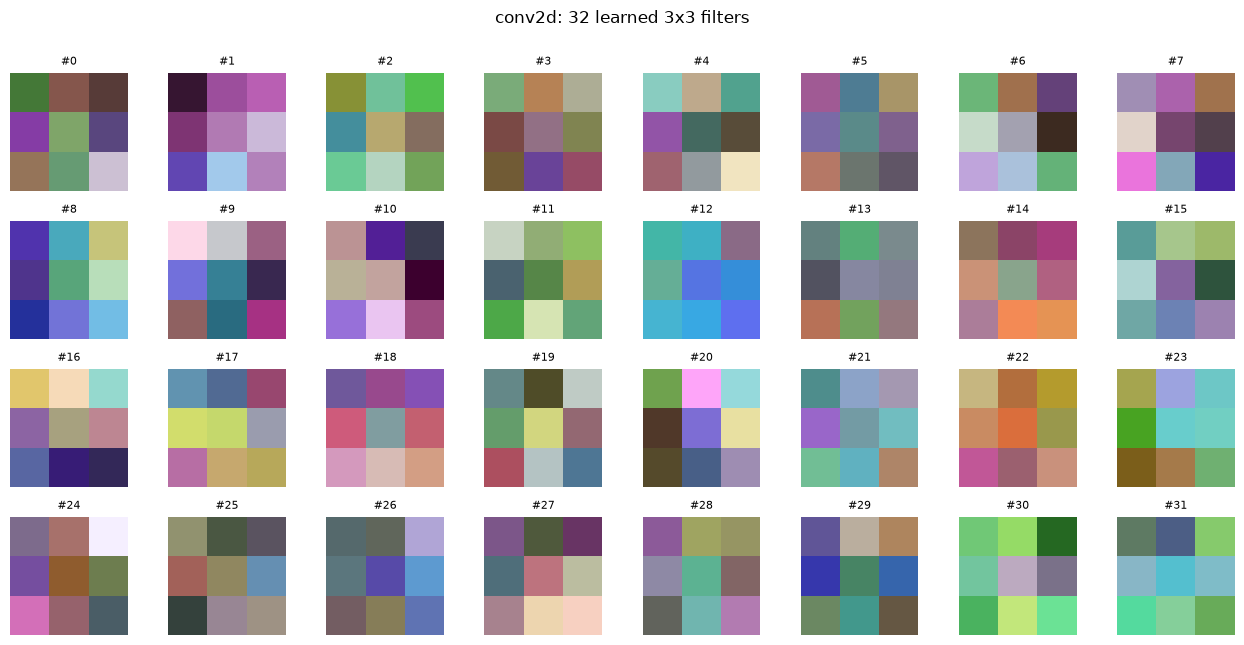

In [40]:
first_conv = next(l for l in cnn.layers if isinstance(l, tf.keras.layers.Conv2D))
filters = first_conv.get_weights()[0]        # shape: (3, 3, 3, 32) = (h, w, in_channels, n_filters)

# Normalise each filter to 0-1 so it can be shown as a small RGB image
f_min, f_max = filters.min(), filters.max()
filters = (filters - f_min) / (f_max - f_min)

n_filters = filters.shape[-1]
cols = 8
rows = int(np.ceil(n_filters / cols))
fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.6))
for i, ax in enumerate(axes.ravel()):
    if i < n_filters:
        ax.imshow(filters[:, :, :, i], interpolation='nearest')
        ax.set_title(f'#{i}', fontsize=8)
    ax.axis('off')
fig.suptitle(f'{first_conv.name}: {n_filters} learned 3x3 filters', y=1.0)
plt.tight_layout()
plt.show()

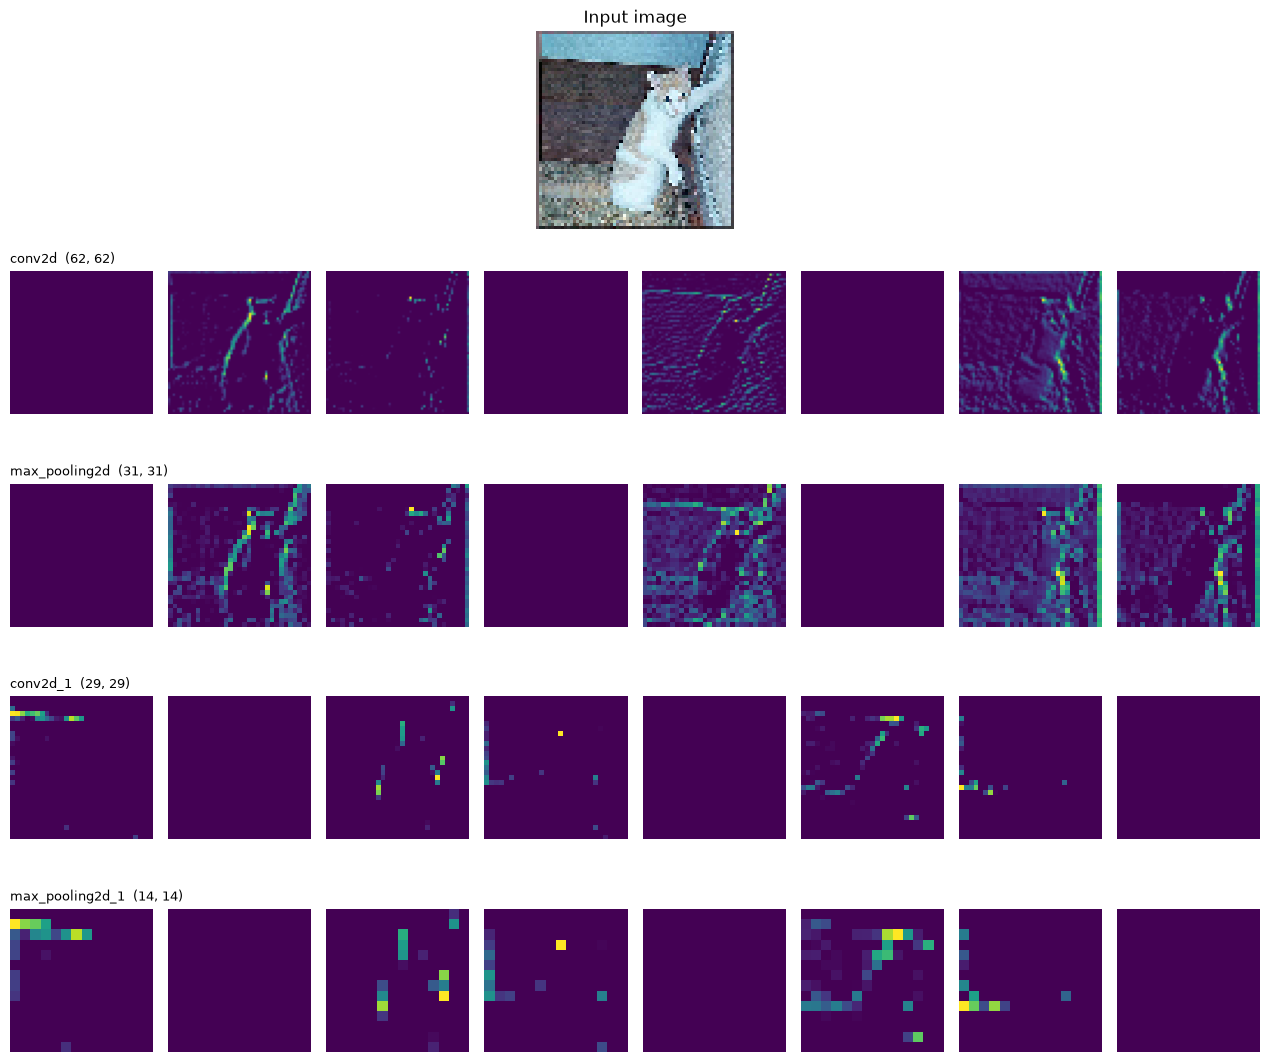

In [41]:
def get_activations(model, x):
    """Runs x through the model layer by layer and keeps the Conv2D / MaxPool outputs."""
    acts, out = [], tf.convert_to_tensor(x)
    for layer in model.layers:
        if isinstance(layer, tf.keras.layers.Flatten):
            break                                   # stop once we leave the convolutional part
        out = layer(out)
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.MaxPool2D)):
            acts.append((layer.name, out.numpy()[0]))
    return acts

def show_feature_maps(img, cols=8):
    acts = get_activations(cnn, np.expand_dims(img, 0))
    fig = plt.figure(figsize=(cols * 1.6, (len(acts) + 1) * 2.2))
    gs = fig.add_gridspec(len(acts) + 1, cols)

    ax = fig.add_subplot(gs[0, :])
    ax.imshow(img); ax.set_title('Input image'); ax.axis('off')

    for r, (name, a) in enumerate(acts, start=1):
        for c in range(min(a.shape[-1], cols)):
            ax = fig.add_subplot(gs[r, c])
            ax.imshow(a[:, :, c], cmap='viridis')
            ax.axis('off')
            if c == 0:
                ax.set_title(f'{name}  {a.shape[:2]}', fontsize=9, loc='left')
    plt.tight_layout()
    plt.show()

show_feature_maps(images[0])

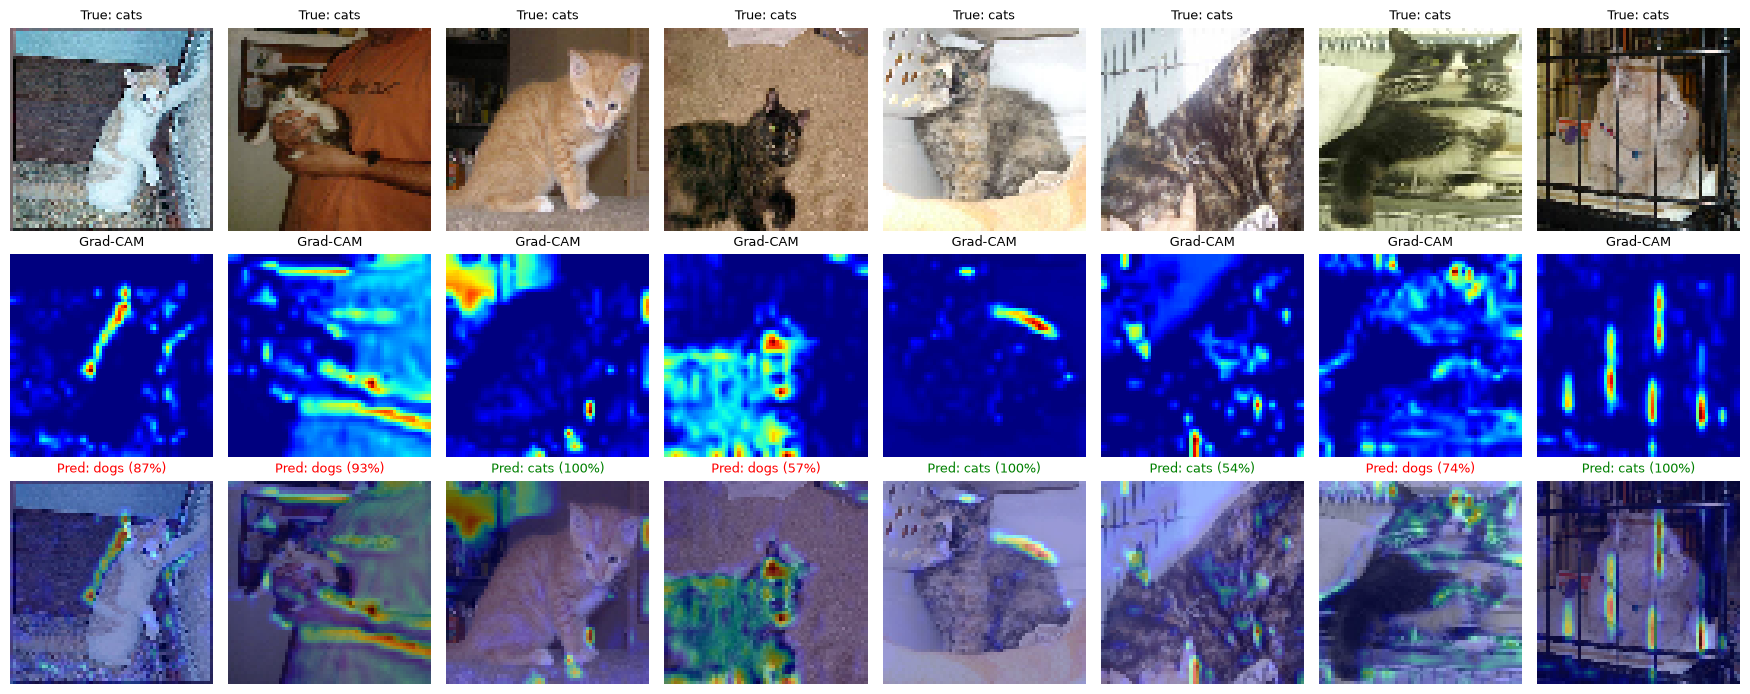

In [42]:
last_conv_name = [l.name for l in cnn.layers if isinstance(l, tf.keras.layers.Conv2D)][-1]

def grad_cam(img):
    """Heatmap (64x64, values 0-1) of the regions that most support the model's predicted class."""
    x = tf.convert_to_tensor(np.expand_dims(img, 0))
    with tf.GradientTape() as tape:
        out = x
        for layer in cnn.layers:
            out = layer(out)
            if layer.name == last_conv_name:
                conv_out = out
                tape.watch(conv_out)
        p = out[:, 0]
        score = tf.where(p >= 0.5, p, 1 - p)       # score of the predicted class
    grads = tape.gradient(score, conv_out)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(weights * conv_out, axis=-1))[0]
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    cam = tf.image.resize(cam[..., None], (64, 64)).numpy()[..., 0]
    return cam

n = 8
fig, axes = plt.subplots(3, n, figsize=(n * 2.2, 7))
for i in range(n):
    img = images[i]
    cam = grad_cam(img)
    p, c = predict_with_confidence(np.expand_dims(img, 0))
    axes[0, i].imshow(img);                    axes[0, i].set_title(f'True: {class_names[int(labels[i])]}', fontsize=9)
    axes[1, i].imshow(cam, cmap='jet');        axes[1, i].set_title('Grad-CAM', fontsize=9)
    axes[2, i].imshow(img); axes[2, i].imshow(cam, cmap='jet', alpha=0.4)
    axes[2, i].set_title(f'Pred: {class_names[p[0]]} ({c[0]*100:.0f}%)', fontsize=9,
                         color='green' if p[0] == int(labels[i]) else 'red')
    for r in range(3):
        axes[r, i].axis('off')
plt.tight_layout()
plt.show()

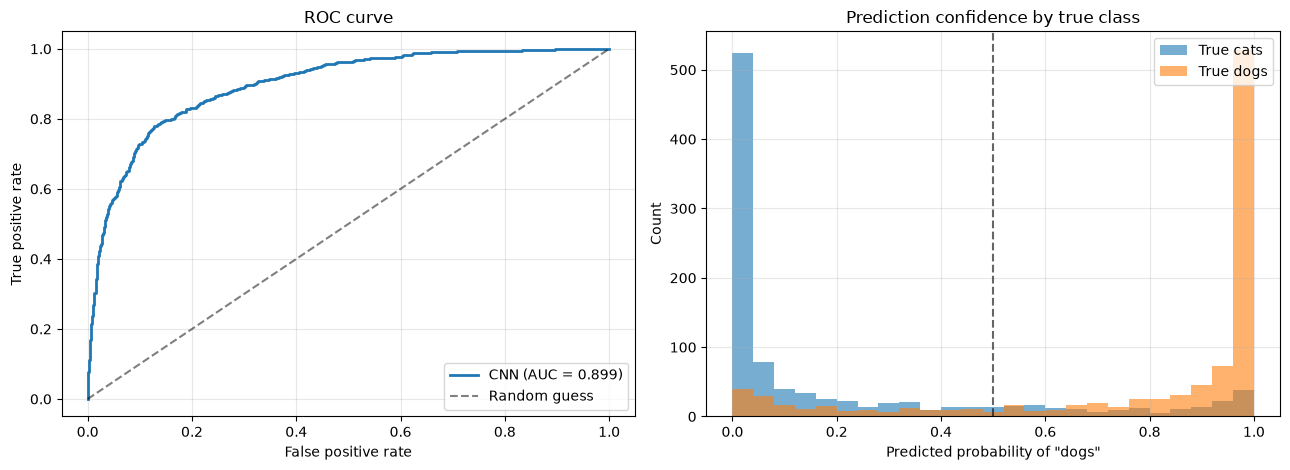

In [43]:
probs = cnn.predict(eval_set, verbose=0).ravel()     # P(class 1) for every test image, in file order
y_true_eval = eval_set.classes

fpr, tpr, _ = roc_curve(y_true_eval, probs)
roc_auc = auc(fpr, tpr)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

ax[0].plot(fpr, tpr, lw=2, label=f'CNN (AUC = {roc_auc:.3f})')
ax[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random guess')
ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate')
ax[0].set_title('ROC curve'); ax[0].legend(loc='lower right'); ax[0].grid(alpha=0.3)

for idx in sorted(idx_to_class):
    ax[1].hist(probs[y_true_eval == idx], bins=25, alpha=0.6, label=f'True {idx_to_class[idx]}')
ax[1].axvline(0.5, color='k', linestyle='--', alpha=0.6)
ax[1].set_xlabel(f'Predicted probability of "{class_names[1]}"'); ax[1].set_ylabel('Count')
ax[1].set_title('Prediction confidence by true class'); ax[1].legend(); ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

362 misclassified out of 2000 test images


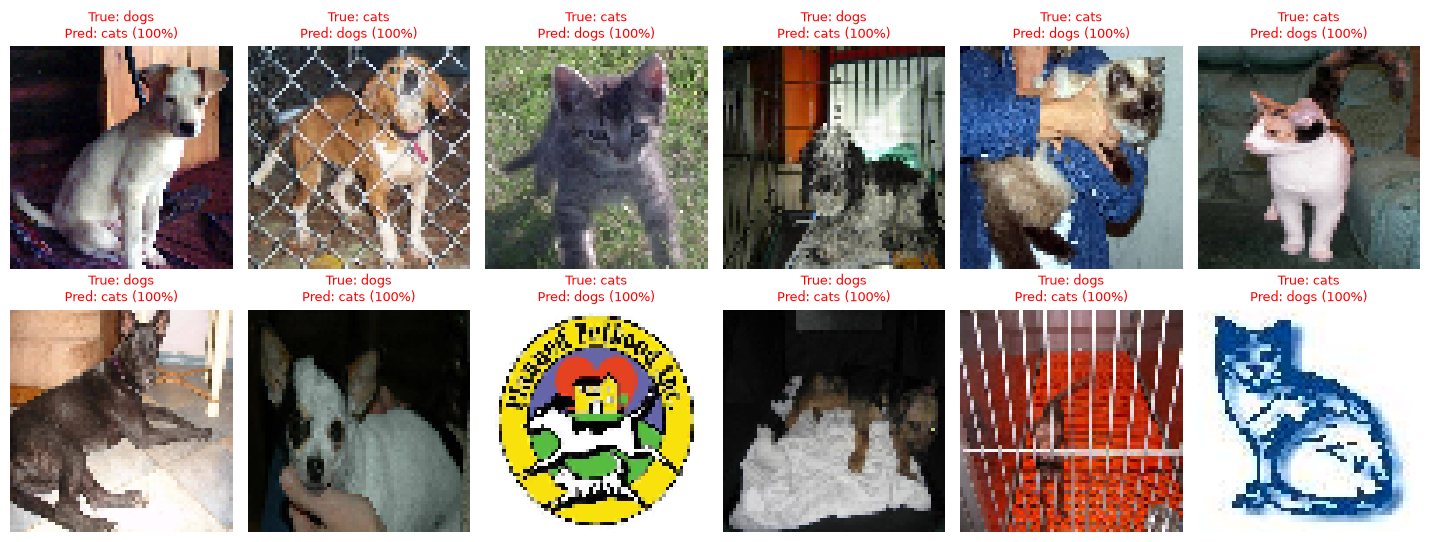

In [44]:
from tensorflow.keras.preprocessing import image as keras_image

y_pred_eval = (probs > 0.5).astype(int)
wrong = np.where(y_pred_eval != y_true_eval)[0]
conf_eval = np.where(y_pred_eval == 1, probs, 1 - probs)
wrong = wrong[np.argsort(-conf_eval[wrong])][:12]          # most confident errors first

print(f'{len(np.where(y_pred_eval != y_true_eval)[0])} misclassified out of {len(y_true_eval)} test images')

if len(wrong):
    cols = 6
    rows = int(np.ceil(len(wrong) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.4, rows * 2.8), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, i in zip(axes.ravel(), wrong):
        ax.imshow(keras_image.load_img(eval_set.filepaths[i], target_size=(64, 64)))
        ax.set_title(f'True: {class_names[y_true_eval[i]]}\nPred: {class_names[y_pred_eval[i]]} ({conf_eval[i]*100:.0f}%)',
                     fontsize=9, color='red')
    plt.tight_layout()
    plt.show()